# 05 · Evaluación final

Evaluación del modelo **congelado** `tronsentinel-onchain-riskset-v0.6.1-20260928` (umbral `0,4288828974`) en:

* **Test interno** (282 filas, 60 riesgosas) — misma cohorte, fechas posteriores a validación.
* **Holdout externo** (286 filas, 99 riesgosas) — cohorte separada, wallets nuevas, abierto **una sola vez** antes del despliegue.

Ambos conjuntos ya fueron abiertos (`governance/data-openings.json`); este notebook **reporta** resultados y no cambia
parámetros, umbral ni variables. Los baselines se entrenan en train y su umbral se elige en validación con la misma regla.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_processing import FEATURE_NAMES, get_split, load_dataset, split_xy
from src.evaluate import classification_metrics, full_report, ppv_at_prevalence, wilson_interval
from src.model import load_model, predict_proba, threshold
from src.train import DEPLOYED_PARAMS, SEED, BalancedGradientBoosting, build_baseline, fit_platt, select_threshold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
MET = ROOT / "results" / "metrics"
dev = load_dataset(ROOT / "data/processed/development_dataset_v6.csv")
ext = load_dataset(ROOT / "data/processed/external_holdout_v6.csv")
X_train, y_train, g_train = split_xy(get_split(dev, "train"))
X_val, y_val, g_val = split_xy(get_split(dev, "validation"))
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

FIG = ROOT / "results" / "figures" / "evaluacion"
REP = ROOT / "results" / "reports"
FIG.mkdir(parents=True, exist_ok=True)
REP.mkdir(parents=True, exist_ok=True)
modelo = load_model(ROOT / "models/model_v0.6.1.json")
UMBRAL = threshold(modelo)
test = get_split(dev, "test")
X_test, y_test, g_test = split_xy(test)
X_ext, y_ext, g_ext = split_xy(ext)

logistica = build_baseline().fit(X_train, y_train)
umbral_log = select_threshold(logistica.predict_proba(X_val)[:, 1], y_val, 0.05)["threshold"]
dummy = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train, y_train)

conjuntos = {"test interno": (X_test, y_test), "holdout externo": (X_ext, y_ext)}
probs = {c: {"TronSentinel v0.6.1": predict_proba(modelo, X),
             "Regresión logística": logistica.predict_proba(X)[:, 1],
             "Dummy estratificado": dummy.predict_proba(X)[:, 1]} for c, (X, _) in conjuntos.items()}
umbrales = {"TronSentinel v0.6.1": UMBRAL, "Regresión logística": umbral_log, "Dummy estratificado": 0.5}
print(f"Umbral del modelo: {UMBRAL:.4f} · umbral de la logística (elegido en validación): {umbral_log:.4f}")

2026-10-23 10:34:27,894 INFO src.data_processing: Dataset development_dataset_v6.csv: 1854 filas, 44 columnas


2026-10-23 10:34:27,906 INFO src.data_processing: Dataset external_holdout_v6.csv: 286 filas, 44 columnas


Umbral del modelo: 0.4289 · umbral de la logística (elegido en validación): 0.8609


## 1. Métricas finales con intervalos de confianza y comparación con baselines

In [2]:
filas, reportes = [], {}
for conjunto, (_, y) in conjuntos.items():
    for nombre, p in probs[conjunto].items():
        r = full_report(y, p, umbrales[nombre])
        reportes[f"{conjunto} · {nombre}"] = r
        filas.append({"conjunto": conjunto, "modelo": nombre, "accuracy": r["accuracy"], "precisión": r["precision"],
                      "recall": r["recall"], "recall IC95": f"{r['recall_ci95'][0]:.3f}–{r['recall_ci95'][1]:.3f}",
                      "FPR": r["fpr"], "FPR IC95": f"{r['fpr_ci95'][0]:.3f}–{r['fpr_ci95'][1]:.3f}",
                      "F1": r["f1"], "ROC-AUC": r["auc"], "PR-AUC": r["auc_pr"], "PR-AUC nulo": r["null_pr_auc"],
                      "Brier": r["brier"]})
final = pd.DataFrame(filas).set_index(["conjunto", "modelo"])
final.to_csv(MET / "evaluacion_final.csv")
final.round(3)

accuracy  precisión  recall  recall IC95  \
conjunto        modelo                                                          
test interno    TronSentinel v0.6.1     0.933      0.860   0.817  0.701–0.894   
                Regresión logística     0.918      0.863   0.733  0.610–0.829   
                Dummy estratificado     0.670      0.200   0.183  0.106–0.299   
holdout externo TronSentinel v0.6.1     0.906      0.919   0.798  0.708–0.865   
                Regresión logística     0.888      0.894   0.768  0.675–0.840   
                Dummy estratificado     0.580      0.316   0.182  0.118–0.269   

                                       FPR     FPR IC95     F1  ROC-AUC  \
conjunto        modelo                                                    
test interno    TronSentinel v0.6.1  0.036  0.018–0.069  0.838    0.967   
                Regresión logística  0.032  0.015–0.064  0.793    0.950   
                Dummy estratificado  0.198  0.151–0.256  0.191    0.493   
holdout externo TronSentinel v0.6.1  0.037  0.018–0.075  0.854    0.962   
                Regresión logística  0.048  0.026–0.089  0.826    0.956   
                Dummy estratificado  0.209  0.156–0.272  0.231    0.487   

                                     PR-AUC  PR-AUC nulo  Brier  
conjunto        modelo                                           
test interno    TronSentinel v0.6.1   0.899        0.213  0.052  
                Regresión logística   0.874        0.213  0.079  
                Dummy estratificado   0.210        0.213  0.330  
holdout externo TronSentinel v0.6.1   0.929        0.346  0.079  
                Regresión logística   0.913        0.346  0.096  
                Dummy estratificado   0.341        0.346  0.420

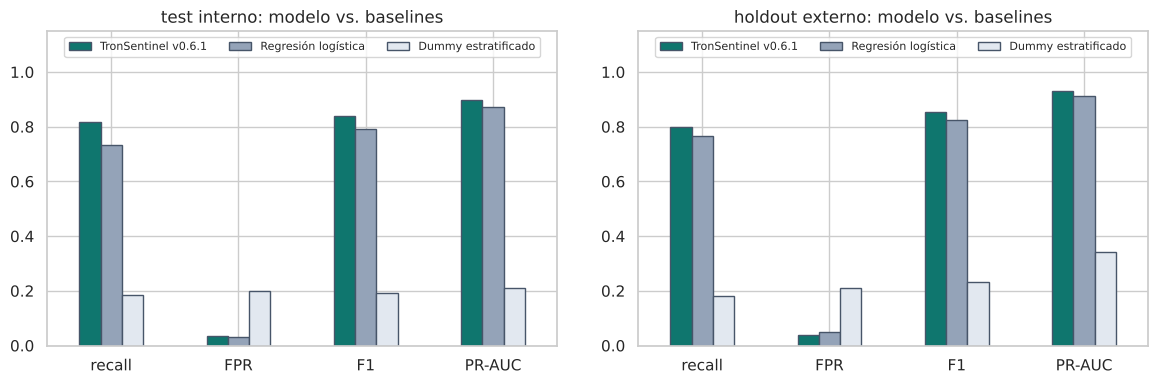

In [3]:
import json
(REP / "evaluacion_final.json").write_text(json.dumps(reportes, indent=2, default=float), encoding="utf-8")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, conjunto in zip(axes, conjuntos):
    datos = final.loc[conjunto][["recall", "FPR", "F1", "PR-AUC"]]
    datos.T.plot.bar(ax=ax, rot=0, color=["#0f766e", "#94a3b8", "#e2e8f0"], edgecolor="#475569")
    ax.set_title(f"{conjunto}: modelo vs. baselines")
    ax.set_ylim(0, 1.15)
    ax.legend(fontsize=8, ncol=3, loc="upper center")
plt.tight_layout()
plt.savefig(FIG / "eval_01_comparacion_baselines.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Matrices de confusión

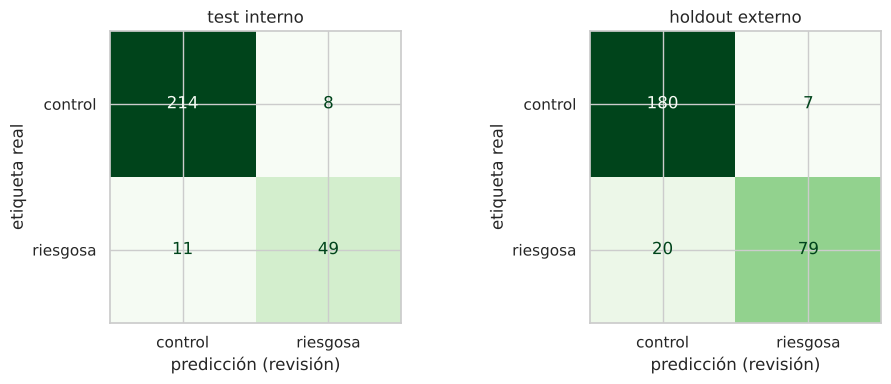

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (conjunto, (_, y)) in zip(axes, conjuntos.items()):
    pred = (probs[conjunto]["TronSentinel v0.6.1"] >= UMBRAL).astype(int)
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["control", "riesgosa"], cmap="Greens",
                                            ax=ax, colorbar=False)
    ax.set_title(conjunto)
    ax.set_xlabel("predicción (revisión)")
    ax.set_ylabel("etiqueta real")
plt.tight_layout()
plt.savefig(FIG / "eval_02_matrices_confusion.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Curvas ROC y Precisión-Recall

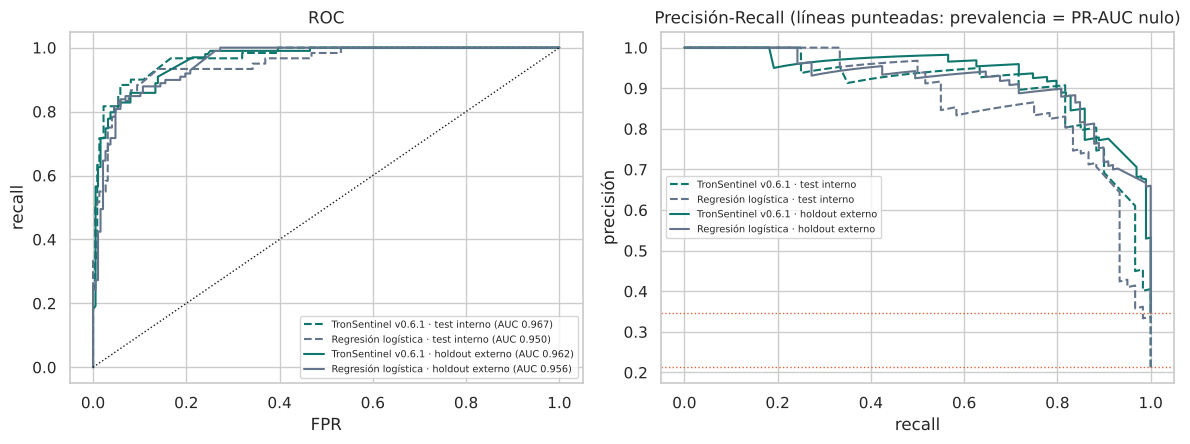

In [5]:
from sklearn.metrics import auc as area, precision_recall_curve, roc_curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for conjunto, (_, y) in conjuntos.items():
    estilo = "-" if conjunto == "holdout externo" else "--"
    for nombre, color in [("TronSentinel v0.6.1", "#0f766e"), ("Regresión logística", "#64748b")]:
        fpr, tpr, _ = roc_curve(y, probs[conjunto][nombre])
        precision, recall, _ = precision_recall_curve(y, probs[conjunto][nombre])
        etiqueta = f"{nombre} · {conjunto}"
        axes[0].plot(fpr, tpr, estilo, color=color, label=f"{etiqueta} (AUC {area(fpr, tpr):.3f})")
        axes[1].plot(recall, precision, estilo, color=color, label=etiqueta)
    axes[1].axhline(y.mean(), ls=":", color="#e0663a", lw=1)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set(title="ROC", xlabel="FPR", ylabel="recall")
axes[1].set(title="Precisión-Recall (líneas punteadas: prevalencia = PR-AUC nulo)", xlabel="recall", ylabel="precisión")
for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG / "eval_03_roc_pr.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Calibración en conjuntos no vistos

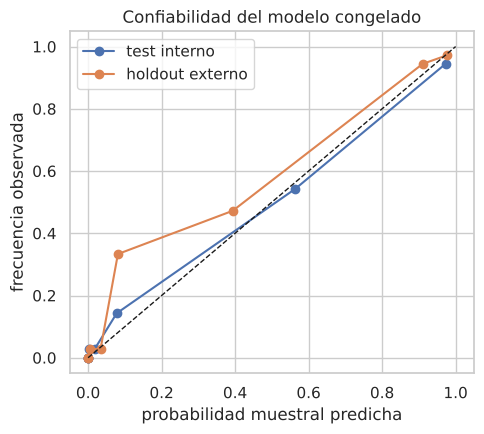

In [6]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5, 4.5))
for conjunto, (_, y) in conjuntos.items():
    frac, media = calibration_curve(y, probs[conjunto]["TronSentinel v0.6.1"], n_bins=8, strategy="quantile")
    ax.plot(media, frac, "o-", label=conjunto)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("probabilidad muestral predicha")
ax.set_ylabel("frecuencia observada")
ax.set_title("Confiabilidad del modelo congelado")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "eval_04_calibracion.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. ¿Qué precisión tendría con la prevalencia real?

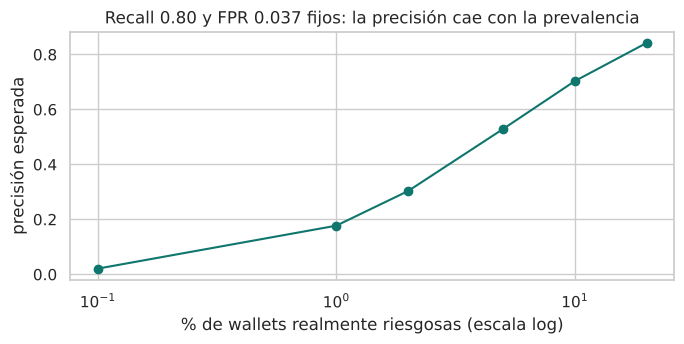

,prevalencia,precisión esperada,alertas falsas por cada verdadera
0,0.200,0.842,0.188
1,0.100,0.703,0.422
2,0.050,0.529,0.891
3,0.020,0.303,2.299
4,0.010,0.177,4.644
5,0.001,0.021,46.863


In [7]:
r = reportes["holdout externo · TronSentinel v0.6.1"]
prevalencias = [0.20, 0.10, 0.05, 0.02, 0.01, 0.001]
tabla_prev = pd.DataFrame({"prevalencia": prevalencias,
                           "precisión esperada": [ppv_at_prevalence(r["recall"], r["fpr"], q) for q in prevalencias]})
tabla_prev["alertas falsas por cada verdadera"] = (1 - tabla_prev["precisión esperada"]) / tabla_prev["precisión esperada"]
tabla_prev.to_csv(MET / "evaluacion_precision_por_prevalencia.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot([q * 100 for q in prevalencias], tabla_prev["precisión esperada"], "o-", color="#0f766e")
ax.set_xscale("log")
ax.set_xlabel("% de wallets realmente riesgosas (escala log)")
ax.set_ylabel("precisión esperada")
ax.set_title(f"Recall {r['recall']:.2f} y FPR {r['fpr']:.3f} fijos: la precisión cae con la prevalencia")
plt.tight_layout()
plt.savefig(FIG / "eval_05_precision_prevalencia.png", dpi=160, bbox_inches="tight")
plt.show()
tabla_prev.round(3)

**Lectura.** Con un 1 % de wallets riesgosas, solo ~18 de cada 100 alertas serían verdaderas. El modelo es útil para
**ordenar** la revisión humana, no para actuar automáticamente sobre una alerta. La interfaz muestra esta advertencia.

## 6. Análisis de errores por subgrupo (volumen de la wallet)

In [8]:
cortes = dev[dev.datasetSplit == "train"].totalAmount.quantile([1 / 3, 2 / 3]).to_numpy()
BANDAS = ["volumen bajo (tercil 1)", "volumen medio (tercil 2)", "volumen alto (tercil 3)"]
filas = []
for conjunto, frame in [("test interno", test), ("holdout externo", ext)]:
    X, y, _ = split_xy(frame)
    pred = (predict_proba(modelo, X) >= UMBRAL).astype(int)
    banda = np.select([frame.totalAmount <= cortes[0], frame.totalAmount <= cortes[1]], BANDAS[:2], BANDAS[2])
    for b in BANDAS:
        m = banda == b
        tp, fn = int(((pred == 1) & (y == 1) & m).sum()), int(((pred == 0) & (y == 1) & m).sum())
        fp, tn = int(((pred == 1) & (y == 0) & m).sum()), int(((pred == 0) & (y == 0) & m).sum())
        _, r_lo, r_hi = wilson_interval(tp, tp + fn)
        filas.append({"conjunto": conjunto, "banda": b, "riesgosas": tp + fn, "controles": fp + tn,
                      "recall": tp / (tp + fn) if tp + fn else np.nan, "recall IC95": f"{r_lo:.2f}–{r_hi:.2f}",
                      "FPR": fp / (fp + tn) if fp + tn else np.nan})
subgrupos = pd.DataFrame(filas).set_index(["conjunto", "banda"])
subgrupos.to_csv(MET / "evaluacion_subgrupos_volumen.csv")
print("Cortes (terciles de totalAmount en train, USDT):", [f"{c:,.0f}" for c in cortes])
subgrupos.round(3)

Cortes (terciles de totalAmount en train, USDT): ['29,254', '611,105']


riesgosas  controles  recall  \
conjunto        banda                                                    
test interno    volumen bajo (tercil 1)           5         92   0.200   
                volumen medio (tercil 2)         21         58   0.857   
                volumen alto (tercil 3)          34         72   0.882   
holdout externo volumen bajo (tercil 1)          19         79   0.368   
                volumen medio (tercil 2)         38         58   0.921   
                volumen alto (tercil 3)          42         50   0.881   

                                         recall IC95    FPR  
conjunto        banda                                        
test interno    volumen bajo (tercil 1)    0.04–0.62  0.011  
                volumen medio (tercil 2)   0.65–0.95  0.069  
                volumen alto (tercil 3)    0.73–0.95  0.042  
holdout externo volumen bajo (tercil 1)    0.19–0.59  0.000  
                volumen medio (tercil 2)   0.79–0.97  0.069  
                volumen alto (tercil 3)    0.75–0.95  0.060

**Lectura.** El desempeño **no es homogéneo**: el modelo detecta mucho peor las wallets riesgosas de bajo volumen (su señal
principal son montos altos; en el holdout externo el recall del tercil bajo es 0,37, IC 0,19–0,59) y, a la inversa, casi todas las falsas alarmas
se concentran en controles de volumen medio y alto (FPR 4–7 % frente a 0–1 % en el tercil bajo). Los intervalos son anchos porque cada banda tiene pocos casos. Este es el principal caso límite: una wallet riesgosa que mueve poco dinero puede recibir "no requiere revisión". La
interfaz incluye un ejemplo real de este falso negativo (`missed-risk`) y el model card lo declara como limitación.

## 7. Qué variables usa el modelo

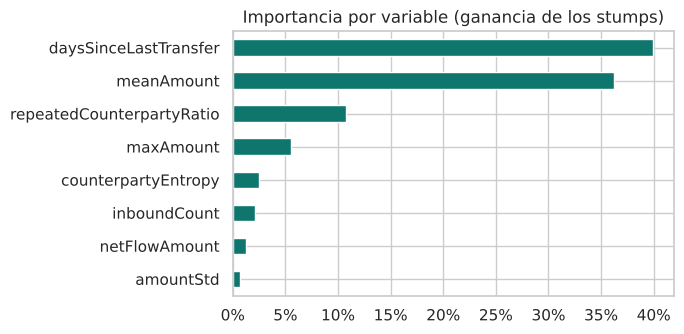

Variables usadas por al menos un árbol: 10 de 38


daysSinceLastTransfer        0.3993
meanAmount                   0.3620
repeatedCounterpartyRatio    0.1076
maxAmount                    0.0553
counterpartyEntropy          0.0249
inboundCount                 0.0214
netFlowAmount                0.0124
amountStd                    0.0073
dtype: float64

In [9]:
from src.model import stump_importance
importancia = stump_importance(modelo)
fig, ax = plt.subplots(figsize=(7, 3.5))
importancia.head(8).iloc[::-1].plot.barh(ax=ax, color="#0f766e")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Importancia por variable (ganancia de los stumps)")
plt.tight_layout()
plt.savefig(FIG / "eval_06_importancia_variables.png", dpi=160, bbox_inches="tight")
plt.show()
print("Variables usadas por al menos un árbol:", len(importancia), "de", len(FEATURE_NAMES))
importancia.head(8).round(4)

Solo 10 de las 38 variables entran en algún árbol, y dos (`daysSinceLastTransfer` y `meanAmount`) concentran ~76 % de la
ganancia (≈ 94 % con la importancia por impureza de scikit-learn que reporta el model card). Es un modelo simple y
explicable, pero frágil: el Workshop S5 (`04_optimizacion.ipynb`) mostró que si falta cualquiera de las dos el recall cae
casi a cero, y que fraccionar una transferencia grande en 5 partes evade ~23 % de las detecciones.

## 8. Explicación de una predicción individual

In [10]:
from src.model import contributions
fila = ext[ext.target == 1].iloc[[0]]
contrib = contributions(modelo, fila[FEATURE_NAMES]).iloc[0]
top = contrib[contrib.abs().sort_values(ascending=False).index[:5]]
p = predict_proba(modelo, fila[FEATURE_NAMES])[0]
print(f"Wallet {fila.address.iloc[0]} · probabilidad muestral {p:.2%} · revisión: {p >= UMBRAL}")
top.round(4).to_frame("contribución al logit")

Wallet TXZ1zP5cR3sJzv4Bfh1G87wCAC8H7FMD6n · probabilidad muestral 90.81% · revisión: True


,contribución al logit
daysSinceLastTransfer,1.2445
meanAmount,0.8046
repeatedCounterpartyRatio,0.2474
maxAmount,0.1397
inboundCount,-0.0950


## 9. Conclusiones

| | Test interno | Holdout externo |
|---|---|---|
| Recall (riesgosas detectadas) | 0,817 | 0,798 |
| FPR (legítimas con alerta) | 0,036 | 0,037 |
| PR-AUC (nulo = prevalencia) | 0,899 (0,213) | 0,929 (0,346) |

* **Funciona bien** en wallets de volumen medio/alto con montos promedio altos y actividad reciente.
* **Supera a los baselines:** el dummy queda en el nivel nulo; la regresión logística tiene buen ranking (ROC/PR-AUC
  cercanos) pero, en el umbral elegido con la misma regla, detecta menos o genera más falsas alarmas (ver tabla).
* **Falla** en riesgosas de bajo volumen, en wallets con datos incompletos (se marcan `NOT_SCORABLE`) y ante evasión por
  fraccionamiento.
* **Uso permitido:** priorizar revisión humana en modo SHADOW. **No** bloquear fondos ni acusar a personas.